In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Memuat hasil deteksi Rule-Based
df_rule = pd.read_csv(
    r"C:\AI-Anomaly-Detection\outputs\hasil_rule_based_detection.csv",
    index_col=0
)

# Memuat hasil pengujian Hybrid AI
df_hybrid = pd.read_csv(
    r"C:\AI-Anomaly-Detection\outputs\hasil_hybrid_ai_testing.csv",
    index_col=0
)

# Mengubah kolom waktu menjadi datetime
df_rule["waktu_tercatat"] = pd.to_datetime(
    df_rule["waktu_tercatat"]
)

df_hybrid["waktu_tercatat"] = pd.to_datetime(
    df_hybrid["waktu_tercatat"]
)

print("===== PEMERIKSAAN DATA =====")

print("Data Rule-Based:", df_rule.shape)
print("Data Hybrid AI:", df_hybrid.shape)

print("\nKolom pada data Hybrid AI:")
print(df_hybrid.columns.tolist())


===== PEMERIKSAAN DATA =====
Data Rule-Based: (38531, 46)
Data Hybrid AI: (11415, 52)

Kolom pada data Hybrid AI:
['suhu', 'kelembaban', 'pm10', 'pm25', 'barometer', 'tvoc', 'waktu_tercatat', 'gap_sec', 'session_id', 'tvoc_duration', 'tvoc_change_flag', 'tvoc_delta', 'barometer_duration', 'barometer_change_flag', 'barometer_delta', 'pm10_duration', 'pm10_change_flag', 'pm10_delta', 'pm25_duration', 'pm25_change_flag', 'pm25_delta', 'gap_panjang_flag', 'awal_sesi_flag', 'pm10_delta_next', 'pm25_delta_next', 'pm10_spike', 'pm25_spike', 'kandidat_spike', 'pm10_spike_reversal', 'pm25_spike_reversal', 'spike_reversal', 'kategori_spike', 'unusual_suhu', 'unusual_kelembaban', 'unusual_pm10', 'unusual_pm25', 'unusual_barometer', 'unusual_tvoc', 'unusual_value', 'stuck_barometer', 'stuck_pm10', 'stuck_pm25', 'stuck_tvoc', 'stuck_value', 'rule_based_anomaly', 'kombinasi_deteksi', 'prediksi_if', 'skor_if', 'ai_anomaly', 'perbandingan_deteksi', 'kategori_hybrid', 'hybrid_anomaly']


In [2]:

print("===== DISTRIBUSI RULE-BASED PADA DATA TESTING =====")

print(
    df_hybrid["rule_based_anomaly"]
    .value_counts()
    .rename(index={
        True: "Kandidat Anomali",
        False: "Normal"
    })
)

print("\n===== DISTRIBUSI ISOLATION FOREST =====")

print(
    df_hybrid["ai_anomaly"]
    .value_counts()
    .rename(index={
        True: "Kandidat Anomali",
        False: "Normal"
    })
)

print("\n===== DISTRIBUSI HYBRID AI =====")

print(
    df_hybrid["hybrid_anomaly"]
    .value_counts()
    .rename(index={
        True: "Kandidat Anomali",
        False: "Normal"
    })
)

print("\n===== KATEGORI HYBRID AI =====")

print(df_hybrid["kategori_hybrid"].value_counts())


===== DISTRIBUSI RULE-BASED PADA DATA TESTING =====
rule_based_anomaly
Kandidat Anomali    6265
Normal              5150
Name: count, dtype: int64

===== DISTRIBUSI ISOLATION FOREST =====
ai_anomaly
Normal              10172
Kandidat Anomali     1243
Name: count, dtype: int64

===== DISTRIBUSI HYBRID AI =====
hybrid_anomaly
Kandidat Anomali    6547
Normal              4868
Name: count, dtype: int64

===== KATEGORI HYBRID AI =====
kategori_hybrid
Anomali - Rule-Based saja    5304
Normal                       4868
Anomali - Rule-Based + AI     961
Anomali - AI saja             282
Name: count, dtype: int64


In [3]:

total_data = len(df_hybrid)

ringkasan_evaluasi = pd.DataFrame({
    "Metode": [
        "Rule-Based",
        "Isolation Forest",
        "Hybrid AI"
    ],
    "Kandidat Anomali": [
        df_hybrid["rule_based_anomaly"].sum(),
        df_hybrid["ai_anomaly"].sum(),
        df_hybrid["hybrid_anomaly"].sum()
    ],
    "Data Normal": [
        (~df_hybrid["rule_based_anomaly"]).sum(),
        (~df_hybrid["ai_anomaly"]).sum(),
        (~df_hybrid["hybrid_anomaly"]).sum()
    ]
})

ringkasan_evaluasi["Persentase Anomali (%)"] = (
    ringkasan_evaluasi["Kandidat Anomali"]
    / total_data * 100
).round(2)

ringkasan_evaluasi["Persentase Normal (%)"] = (
    ringkasan_evaluasi["Data Normal"]
    / total_data * 100
).round(2)

print("===== PERBANDINGAN HASIL DETEKSI =====")
display(ringkasan_evaluasi)

print("\nTotal data testing:", total_data)


===== PERBANDINGAN HASIL DETEKSI =====


,Metode,Kandidat Anomali,Data Normal,Persentase Anomali (%),Persentase Normal (%)
0,Rule-Based,6265,5150,54.88,45.12
1,Isolation Forest,1243,10172,10.89,89.11
2,Hybrid AI,6547,4868,57.35,42.65



Total data testing: 11415


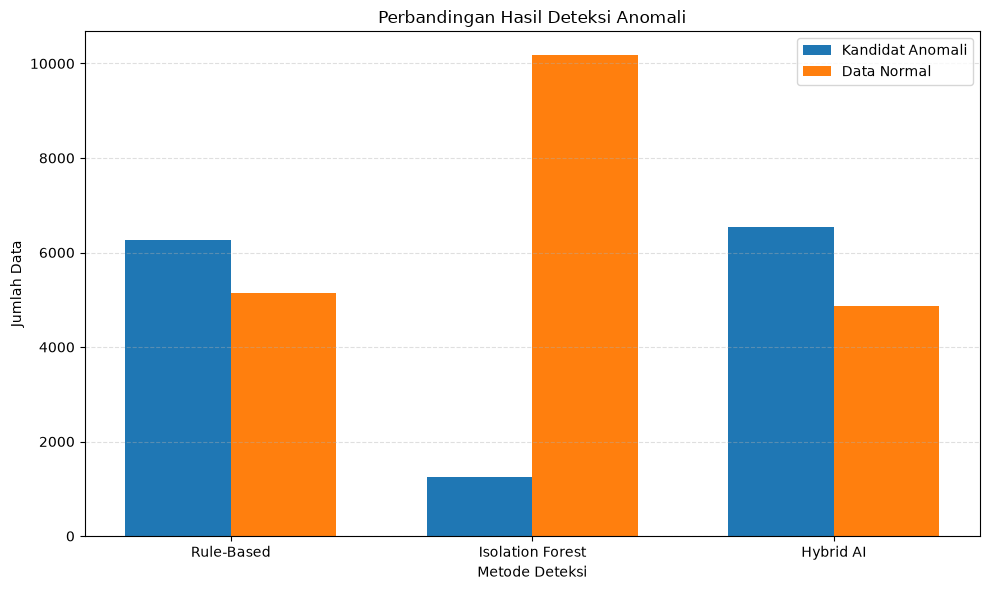

In [4]:

# Menyiapkan data visualisasi
metode = ringkasan_evaluasi["Metode"]

x = np.arange(len(metode))
lebar = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - lebar/2,
    ringkasan_evaluasi["Kandidat Anomali"],
    lebar,
    label="Kandidat Anomali"
)

plt.bar(
    x + lebar/2,
    ringkasan_evaluasi["Data Normal"],
    lebar,
    label="Data Normal"
)

plt.title("Perbandingan Hasil Deteksi Anomali")
plt.xlabel("Metode Deteksi")
plt.ylabel("Jumlah Data")
plt.xticks(x, metode)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


In [5]:

# Membuat tabel silang hasil deteksi
tabel_kesesuaian = pd.crosstab(
    df_hybrid["rule_based_anomaly"].map({
        True: "Anomali Rule-Based",
        False: "Normal Rule-Based"
    }),
    df_hybrid["ai_anomaly"].map({
        True: "Anomali Isolation Forest",
        False: "Normal Isolation Forest"
    })
)

print("===== KESESUAIAN DETEKSI ANTAR-METODE =====")
display(tabel_kesesuaian)

print("\n===== RINGKASAN KESESUAIAN =====")

print(
    "Terdeteksi kedua metode:",
    ((df_hybrid["rule_based_anomaly"]) &
     (df_hybrid["ai_anomaly"])).sum()
)

print(
    "Rule-Based saja:",
    ((df_hybrid["rule_based_anomaly"]) &
     (~df_hybrid["ai_anomaly"])).sum()
)

print(
    "Isolation Forest saja:",
    ((~df_hybrid["rule_based_anomaly"]) &
     (df_hybrid["ai_anomaly"])).sum()
)

print(
    "Normal menurut kedua metode:",
    ((~df_hybrid["rule_based_anomaly"]) &
     (~df_hybrid["ai_anomaly"])).sum()
)


===== KESESUAIAN DETEKSI ANTAR-METODE =====


ai_anomaly,Anomali Isolation Forest,Normal Isolation Forest
rule_based_anomaly,,
Anomali Rule-Based,961,5304
Normal Rule-Based,282,4868



===== RINGKASAN KESESUAIAN =====
Terdeteksi kedua metode: 961
Rule-Based saja: 5304
Isolation Forest saja: 282
Normal menurut kedua metode: 4868


In [6]:

total_data = len(df_hybrid)

kedua_anomali = (
    df_hybrid["rule_based_anomaly"] &
    df_hybrid["ai_anomaly"]
).sum()

keduanya_normal = (
    ~df_hybrid["rule_based_anomaly"] &
    ~df_hybrid["ai_anomaly"]
).sum()

sepakat = kedua_anomali + keduanya_normal
tidak_sepakat = total_data - sepakat

gabungan_anomali = df_hybrid["hybrid_anomaly"].sum()

tingkat_kesepakatan = sepakat / total_data * 100
tingkat_perbedaan = tidak_sepakat / total_data * 100
overlap_anomali = kedua_anomali / gabungan_anomali * 100

print("===== ANALISIS KESEPAKATAN METODE =====")

print("Total data testing:", total_data)

print(
    f"Data yang disepakati: {sepakat} "
    f"({tingkat_kesepakatan:.2f}%)"
)

print(
    f"Data yang berbeda: {tidak_sepakat} "
    f"({tingkat_perbedaan:.2f}%)"
)

print(
    f"Overlap kandidat anomali: {kedua_anomali} "
    f"({overlap_anomali:.2f}% dari gabungan anomali)"
)


===== ANALISIS KESEPAKATAN METODE =====
Total data testing: 11415
Data yang disepakati: 5829 (51.06%)
Data yang berbeda: 5586 (48.94%)
Overlap kandidat anomali: 961 (14.68% dari gabungan anomali)


In [7]:

ringkasan_sesi = (
    df_hybrid
    .groupby("session_id")
    .agg(
        jumlah_data=("hybrid_anomaly", "count"),
        rule_based=("rule_based_anomaly", "sum"),
        isolation_forest=("ai_anomaly", "sum"),
        hybrid_ai=("hybrid_anomaly", "sum")
    )
)

# Menghitung persentase kandidat anomali per sesi
ringkasan_sesi["persentase_hybrid"] = (
    ringkasan_sesi["hybrid_ai"]
    / ringkasan_sesi["jumlah_data"] * 100
).round(2)

ringkasan_sesi = ringkasan_sesi.sort_values(
    "persentase_hybrid",
    ascending=False
)

print("===== DISTRIBUSI DETEKSI ANOMALI PER SESI =====")
display(ringkasan_sesi)

print("\nJumlah sesi testing:", len(ringkasan_sesi))
print(
    "Total kandidat Hybrid AI:",
    ringkasan_sesi["hybrid_ai"].sum()
)


===== DISTRIBUSI DETEKSI ANOMALI PER SESI =====


,jumlah_data,rule_based,isolation_forest,hybrid_ai,persentase_hybrid
session_id,,,,,
48,1115,1115,360,1115,100.00
50,1238,1238,386,1238,100.00
46,1332,723,87,757,56.83
47,1273,621,85,658,51.69
44,1287,605,90,658,51.13
45,1284,611,23,623,48.52
42,1150,498,89,557,48.43
49,1271,463,50,493,38.79
43,1214,381,66,431,35.50



Jumlah sesi testing: 11
Total kandidat Hybrid AI: 6547


In [8]:

# Memeriksa dua sesi dengan deteksi 100%
sesi_pemeriksaan = [48, 50]

kolom_flag = [
    "kandidat_spike",
    "stuck_value",
    "unusual_value",
    "spike_reversal",
    "unusual_suhu",
    "unusual_kelembaban",
    "unusual_pm10",
    "unusual_pm25",
    "unusual_barometer",
    "unusual_tvoc",
    "stuck_barometer",
    "stuck_pm10",
    "stuck_pm25",
    "stuck_tvoc"
]

ringkasan_penyebab = (
    df_hybrid[df_hybrid["session_id"].isin(sesi_pemeriksaan)]
    .groupby("session_id")[kolom_flag]
    .sum()
)

print("===== PENYEBAB DETEKSI SESSION 48 DAN 50 =====")
display(ringkasan_penyebab)

print("\n===== PERSENTASE SETIAP FLAG =====")

persentase_flag = (
    df_hybrid[df_hybrid["session_id"].isin(sesi_pemeriksaan)]
    .groupby("session_id")[kolom_flag]
    .mean() * 100
)

display(persentase_flag.round(2))


===== PENYEBAB DETEKSI SESSION 48 DAN 50 =====


,kandidat_spike,stuck_value,unusual_value,spike_reversal,unusual_suhu,unusual_kelembaban,unusual_pm10,unusual_pm25,unusual_barometer,unusual_tvoc,stuck_barometer,stuck_pm10,stuck_pm25,stuck_tvoc
session_id,,,,,,,,,,,,,,
48,1,363,1115,0,129,0,0,0,1115,1115,0,0,0,363
50,4,292,1238,2,102,0,0,0,1238,1238,0,0,0,292



===== PERSENTASE SETIAP FLAG =====


,kandidat_spike,stuck_value,unusual_value,spike_reversal,unusual_suhu,unusual_kelembaban,unusual_pm10,unusual_pm25,unusual_barometer,unusual_tvoc,stuck_barometer,stuck_pm10,stuck_pm25,stuck_tvoc
session_id,,,,,,,,,,,,,,
48,0.09,32.56,100.0,0.00,11.57,0.0,0.0,0.0,100.0,100.0,0.0,0.0,0.0,32.56
50,0.32,23.59,100.0,0.16,8.24,0.0,0.0,0.0,100.0,100.0,0.0,0.0,0.0,23.59


In [9]:

sensor_pemeriksaan = [
    "barometer",
    "tvoc",
    "suhu",
    "kelembaban",
    "pm10",
    "pm25"
]

ringkasan_sensor_sesi = (
    df_hybrid[
        df_hybrid["session_id"].isin([48, 50])
    ]
    .groupby("session_id")[sensor_pemeriksaan]
    .agg(["min", "median", "max", "nunique"])
)

print("===== KARAKTERISTIK SENSOR SESSION 48 DAN 50 =====")
display(ringkasan_sensor_sesi)


===== KARAKTERISTIK SENSOR SESSION 48 DAN 50 =====


barometer                            tvoc                          \
                 min  median     max nunique     min  median     max nunique   
session_id                                                                     
48            754.22  756.41  758.11     333   83.45  100.22  125.42       6   
50            750.57  753.67  754.88     344  117.01  133.84  167.57       7   

             suhu         ... kelembaban          pm10                       \
              min median  ...        max nunique   min median   max nunique   
session_id                ...                                                 
48          28.30  30.39  ...         65      32  12.0   35.0  69.0      55   
50          26.12  29.59  ...         76      45   0.0   30.0  58.0      49   

           pm25                       
            min median   max nunique  
session_id                            
48          5.0   17.0  34.0      28  
50          0.0   15.0  27.0      25  

[2 rows x 24 columns]

In [10]:

# Membandingkan median sensor pada setiap sesi testing
perbandingan_sensor = (
    df_hybrid
    .groupby("session_id")
    .agg(
        median_barometer=("barometer", "median"),
        min_barometer=("barometer", "min"),
        max_barometer=("barometer", "max"),
        median_tvoc=("tvoc", "median"),
        min_tvoc=("tvoc", "min"),
        max_tvoc=("tvoc", "max")
    )
)

print("===== PERBANDINGAN BAROMETER DAN TVOC ANTAR-SESI =====")
display(perbandingan_sensor.round(2))


===== PERBANDINGAN BAROMETER DAN TVOC ANTAR-SESI =====


,median_barometer,min_barometer,max_barometer,median_tvoc,min_tvoc,max_tvoc
session_id,,,,,,
42,705.02,702.38,706.33,696.08,678.31,722.78
43,700.96,699.07,702.69,740.63,722.78,767.45
44,698.51,696.64,699.80,776.40,758.50,794.34
45,703.83,701.79,705.22,704.97,696.08,731.70
46,703.43,701.05,704.54,713.87,696.08,740.63
47,701.84,699.79,702.64,731.70,722.78,758.50
48,756.41,754.22,758.11,100.22,83.45,125.42
49,703.18,701.20,704.35,713.87,704.97,740.63
50,753.67,750.57,754.88,133.84,117.01,167.57


In [11]:

# Memeriksa waktu dan nilai sensor pada batas sesi
sesi_transisi = [47, 48, 49, 50, 51]

kolom_pemeriksaan = [
    "session_id",
    "waktu_tercatat",
    "barometer",
    "tvoc",
    "suhu",
    "kelembaban",
    "pm10",
    "pm25"
]

data_transisi = df_hybrid[
    df_hybrid["session_id"].isin(sesi_transisi)
].sort_values(["session_id", "waktu_tercatat"])

print("===== 3 DATA PERTAMA SETIAP SESI =====")

display(
    data_transisi
    .groupby("session_id")
    .head(3)[kolom_pemeriksaan]
)

print("\n===== 3 DATA TERAKHIR SETIAP SESI =====")

display(
    data_transisi
    .groupby("session_id")
    .tail(3)[kolom_pemeriksaan]
)


===== 3 DATA PERTAMA SETIAP SESI =====


,session_id,waktu_tercatat,barometer,tvoc,suhu,kelembaban,pm10,pm25
id_monitoring_udara,,,,,,,,
197843,47,2026-11-02 10:28:49,702.57,722.78,29.09,51,25.0,11.0
197844,47,2026-11-02 10:29:54,702.49,722.78,29.09,50,24.0,12.0
197845,47,2026-11-02 10:30:58,702.49,722.78,29.19,49,24.0,12.0
199116,48,2026-11-04 11:08:27,756.38,100.22,37.24,41,24.0,13.0
199117,48,2026-11-04 11:09:30,756.32,100.22,37.44,40,27.0,14.0
199118,48,2026-11-04 11:10:33,756.35,100.22,37.54,40,29.0,14.0
200231,49,2026-11-09 10:27:35,703.94,704.97,37.34,37,39.0,18.0
200232,49,2026-11-09 10:28:39,703.90,704.97,37.83,37,39.0,18.0
200233,49,2026-11-09 10:29:42,703.96,704.97,38.23,35,36.0,17.0



===== 3 DATA TERAKHIR SETIAP SESI =====


,session_id,waktu_tercatat,barometer,tvoc,suhu,kelembaban,pm10,pm25
id_monitoring_udara,,,,,,,,
199113,47,2026-11-03 09:36:07,702.02,731.70,28.80,50,5.0,1.0
199114,47,2026-11-03 09:37:11,702.04,731.70,28.80,49,2.0,1.0
199115,47,2026-11-03 09:38:16,702.04,731.70,28.90,52,3.0,2.0
200228,48,2026-11-05 07:10:42,757.24,91.83,30.39,56,46.0,22.0
200229,48,2026-11-05 07:11:47,757.27,91.83,30.49,57,50.0,22.0
200230,48,2026-11-05 07:12:52,757.27,91.83,30.58,57,47.0,22.0
201499,49,2026-11-10 09:20:50,703.63,713.87,34.76,42,43.0,21.0
201500,49,2026-11-10 09:21:55,703.60,713.87,34.56,42,44.0,22.0
201501,49,2026-11-10 09:23:00,703.59,713.87,34.26,42,43.0,20.0


In [12]:

# Membandingkan median barometer dan TVOC seluruh sesi
perbandingan_semua_sesi = (
    df_rule
    .groupby("session_id")
    .agg(
        jumlah_data=("barometer", "count"),
        median_barometer=("barometer", "median"),
        median_tvoc=("tvoc", "median"),
        min_barometer=("barometer", "min"),
        max_barometer=("barometer", "max"),
        min_tvoc=("tvoc", "min"),
        max_tvoc=("tvoc", "max")
    )
)

perbandingan_semua_sesi["kelompok_data"] = np.where(
    perbandingan_semua_sesi.index <= 41,
    "Training",
    "Testing"
)

print("===== PERBANDINGAN SELURUH SESI =====")
display(perbandingan_semua_sesi.round(2))


===== PERBANDINGAN SELURUH SESI =====


,jumlah_data,median_barometer,median_tvoc,min_barometer,max_barometer,min_tvoc,max_tvoc,kelompok_data
session_id,,,,,,,,
1,1136,701.68,731.70,699.32,702.81,722.78,758.50,Training
2,1289,703.42,713.87,701.55,704.56,696.08,731.70,Training
3,282,697.98,776.40,697.46,699.88,758.50,785.37,Training
4,746,699.95,758.50,699.07,701.27,740.63,767.45,Training
5,1211,701.76,731.70,699.69,702.63,722.78,758.50,Training
6,1191,698.20,776.40,696.08,699.51,758.50,803.32,Training
7,1065,701.70,731.70,699.22,702.98,722.78,767.45,Training
8,1046,700.56,749.56,698.52,701.71,731.70,776.40,Training
9,1143,699.05,767.45,697.27,700.75,749.56,785.37,Training


In [13]:

import joblib

# Memuat model Hybrid AI
model_if = joblib.load(
    r"C:\AI-Anomaly-Detection\models\hybrid_isolation_forest.joblib"
)

# Menggunakan 20 fitur yang sama saat pelatihan
sensor_features = [
    "suhu", "kelembaban", "pm10", "pm25", "barometer", "tvoc"
]

temporal_features = [
    "tvoc_duration", "tvoc_change_flag", "tvoc_delta",
    "barometer_duration", "barometer_change_flag", "barometer_delta",
    "pm10_duration", "pm10_change_flag", "pm10_delta",
    "pm25_duration", "pm25_change_flag", "pm25_delta",
    "gap_panjang_flag", "awal_sesi_flag"
]

feature_columns = sensor_features + temporal_features

# Mengambil sesi yang akan dibandingkan
sesi_pemeriksaan = [12, 13, 15, 48, 50]

data_model = df_rule[
    df_rule["session_id"].isin(sesi_pemeriksaan)
].copy()

X_pemeriksaan = data_model[feature_columns]

# Prediksi dan skor Isolation Forest
data_model["prediksi_if"] = model_if.predict(X_pemeriksaan)
data_model["skor_if"] = model_if.decision_function(X_pemeriksaan)
data_model["ai_anomaly"] = data_model["prediksi_if"] == -1

# Ringkasan hasil per sesi
ringkasan_model_sesi = (
    data_model
    .groupby("session_id")
    .agg(
        jumlah_data=("ai_anomaly", "size"),
        jumlah_anomali_ai=("ai_anomaly", "sum"),
        median_skor=("skor_if", "median"),
        skor_terendah=("skor_if", "min"),
        skor_tertinggi=("skor_if", "max")
    )
)

ringkasan_model_sesi["persentase_anomali"] = (
    ringkasan_model_sesi["jumlah_anomali_ai"]
    / ringkasan_model_sesi["jumlah_data"] * 100
)

print("===== PENILAIAN ISOLATION FOREST PER SESI =====")
display(ringkasan_model_sesi.round(4))


===== PENILAIAN ISOLATION FOREST PER SESI =====


,jumlah_data,jumlah_anomali_ai,median_skor,skor_terendah,skor_tertinggi,persentase_anomali
session_id,,,,,,
12,7,1,0.0428,-0.0477,0.0504,14.2857
13,1011,259,0.0350,-0.1500,0.0779,25.6182
15,1155,413,0.0181,-0.1508,0.0840,35.7576
48,1115,360,0.0226,-0.1202,0.0713,32.2870
50,1238,386,0.0256,-0.1369,0.0813,31.1793


In [14]:

# Membandingkan karakteristik sensor berdasarkan prediksi AI
kolom_sensor = [
    "suhu", "kelembaban", "pm10",
    "pm25", "barometer", "tvoc"
]

perbandingan_ai_sensor = (
    data_model[
        data_model["session_id"].isin([48, 50])
    ]
    .groupby(["session_id", "ai_anomaly"])[kolom_sensor]
    .median()
)

print("===== MEDIAN SENSOR BERDASARKAN PREDIKSI AI =====")
display(perbandingan_ai_sensor.round(2))


===== MEDIAN SENSOR BERDASARKAN PREDIKSI AI =====


suhu  kelembaban  pm10  pm25  barometer    tvoc
session_id ai_anomaly                                                  
48         False       30.29        60.0  35.0  17.0     756.50  100.22
           True        30.68        58.0  34.0  16.5     756.28  108.61
50         False       28.90        66.0  31.0  16.0     753.75  133.84
           True        33.02        51.0  19.0  10.0     753.30  133.84

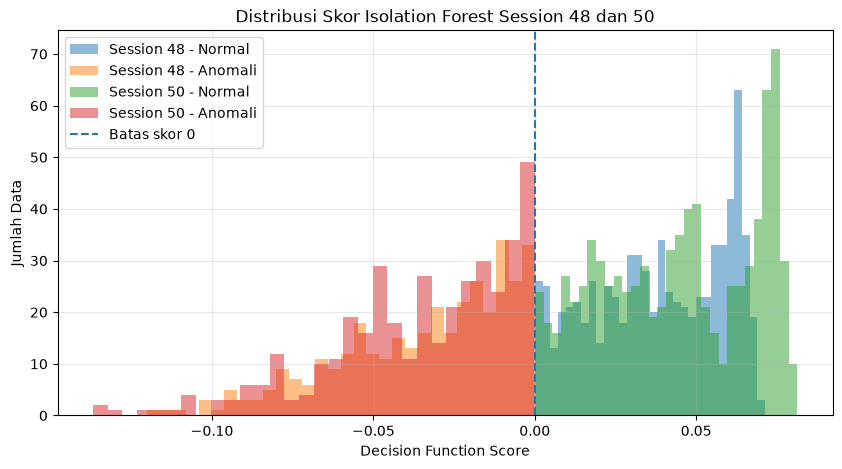

In [15]:

# Membandingkan distribusi skor AI per sesi
plt.figure(figsize=(10, 5))

for sesi in [48, 50]:
    subset = data_model[data_model["session_id"] == sesi]

    plt.hist(
        subset.loc[subset["ai_anomaly"] == False, "skor_if"],
        bins=30,
        alpha=0.5,
        label=f"Session {sesi} - Normal"
    )

    plt.hist(
        subset.loc[subset["ai_anomaly"] == True, "skor_if"],
        bins=30,
        alpha=0.5,
        label=f"Session {sesi} - Anomali"
    )

plt.axvline(0, linestyle="--", label="Batas skor 0")
plt.title("Distribusi Skor Isolation Forest Session 48 dan 50")
plt.xlabel("Decision Function Score")
plt.ylabel("Jumlah Data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



# 10. Kesimpulan Evaluasi Model

Berdasarkan hasil evaluasi pada 11.415 data testing, diperoleh hasil:

1. Rule-Based mendeteksi 6.265 kandidat anomali (54,88%).
2. Isolation Forest mendeteksi 1.243 kandidat anomali (10,89%).
3. Hybrid AI mendeteksi 6.547 kandidat anomali (57,35%).

Hasil perbandingan Rule-Based dan Isolation Forest menunjukkan:
- 961 data terdeteksi anomali oleh kedua metode.
- 5.304 data hanya terdeteksi Rule-Based.
- 282 data hanya terdeteksi Isolation Forest.
- 4.868 data dinyatakan normal oleh kedua metode.

Tingkat kesesuaian kedua metode sebesar 51,06%.

Pemeriksaan khusus pada session 48 dan 50 menunjukkan adanya pergeseran distribusi barometer dan TVOC. Rule-Based menandai seluruh data pada kedua sesi sebagai kandidat anomali, sedangkan Isolation Forest memberikan deteksi yang lebih selektif.

## 11. Keterbatasan Evaluasi

1. Dataset belum memiliki label ground truth sehingga akurasi, precision, recall, dan F1-score belum dapat dihitung secara valid.
2. Hasil deteksi merupakan kandidat anomali yang masih membutuhkan pemeriksaan lebih lanjut.
3. Threshold Rule-Based masih menggunakan batas yang ditentukan berdasarkan karakteristik dataset.
4. Isolation Forest belum dapat memastikan apakah suatu kondisi merupakan kerusakan sensor atau perubahan lingkungan yang sebenarnya.

## 12. Kesimpulan Akhir

Metode Hybrid AI menggabungkan hasil deteksi Rule-Based dan Isolation Forest untuk memperoleh kandidat anomali dari berbagai karakteristik data sensor.

Hasil pengembangan ini menjadi dasar untuk membangun pipeline deteksi anomali dan mengintegrasikannya dengan Telegram Bot agar hasil deteksi dapat dilaporkan secara otomatis.
